# XGBoost Training Notebook

In [1]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Tải từ điển stopwords của nltk (nếu chưa tải)
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 1. Load Dataset

In [2]:
# ==========================================
# 1. Load Dataset
# ========================================== 
clean_df = pd.read_csv("synthetic_emails.csv")
poisoned_df = pd.read_csv("synthetic_emails_poisoned.csv")


## 2. Data Filtering

In [3]:
# ==========================================
# 2. Data Filtering
# ==========================================
# Gộp subject và body thành 1 cột text hoàn chỉnh, xử lý các giá trị NaN
clean_df['text'] = clean_df['subject'].fillna("") + " " + clean_df['body'].fillna("")
poisoned_df['text'] = poisoned_df['subject'].fillna("") + " " + poisoned_df['body'].fillna("")

# So sánh từng cặp: Trích xuất các chỉ mục mà email bị poison KHÁC với email clean
modified_indices = clean_df['text'] != poisoned_df['text']

# Giữ lại các cặp bị biến đổi (loại bỏ hoàn toàn các email giống hệt nhau)
clean_filtered = clean_df[modified_indices].copy()
poisoned_filtered = poisoned_df[modified_indices].copy()

## 3. Create Target Labels

In [4]:
# ==========================================
# 3. Create Target Labels
# ==========================================
clean_filtered['target'] = 0      # Clean BEC
poisoned_filtered['target'] = 1   # Poisoned BEC

# 4. Combine Dataset

In [5]:
# ==========================================
# 4. Combine Dataset
# ==========================================
df = pd.concat([clean_filtered, poisoned_filtered], ignore_index=True)

# 5. Text Preprocessing

In [6]:
# ==========================================
# 5. Text Preprocessing 
# ==========================================
def preprocess_text(text):
    text = str(text).lower()
    # Loại bỏ khoảng trắng thừa nhưng GIỮ LẠI toàn bộ các ký tự (bao gồm cả dấu câu)
    # vì dấu câu hoặc các ký tự lạ chính là dấu hiệu của Poisoned BEC.
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['processed_text'] = df['text'].apply(preprocess_text)

## 6. TF-IDF Vectorization

In [7]:
# ==========================================
# 6. TF-IDF Vectorization 
# ==========================================
# Thay đổi analyzer sang 'char_wb' và tăng ngram_range để bắt được các cụm ký tự lạ
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), max_features=10000)
X = vectorizer.fit_transform(df['processed_text'])
y = df['target']

## 7. Train/Test Split

In [8]:
# ==========================================
# 7. Train/Test Split
# ==========================================
# Chia dữ liệu theo tỷ lệ 80/20 và sử dụng stratify để cân bằng nhãn ở cả 2 tập
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 8. Model Training (XGBoost)

In [9]:
# ==========================================
# 8. Model Training (XGBoost) - (Cập nhật)
# ==========================================
xgb_model = XGBClassifier(
    n_estimators=300,         # Tăng số cây vì character-level có nhiều patterns hơn
    learning_rate=0.1,        
    max_depth=6,              
    subsample=0.8,            
    colsample_bytree=0.8,     
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)

# Huấn luyện mô hình
xgb_model.fit(X_train, y_train)

d:\Conda\envs\aic211\lib\site-packages\xgboost\training.py:200: UserWarning: [23:28:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


### 9. Evaluation

9. Evaluating model...

     ĐÁNH GIÁ MÔ HÌNH XGBOOST
Accuracy:  0.9558
Precision: 0.9538
Recall:    0.9578
F1-score:  0.9558

Classification Report:
                  precision    recall  f1-score   support

   Clean BEC (0)       0.96      0.95      0.96       238
Poisoned BEC (1)       0.95      0.96      0.96       237

        accuracy                           0.96       475
       macro avg       0.96      0.96      0.96       475
    weighted avg       0.96      0.96      0.96       475



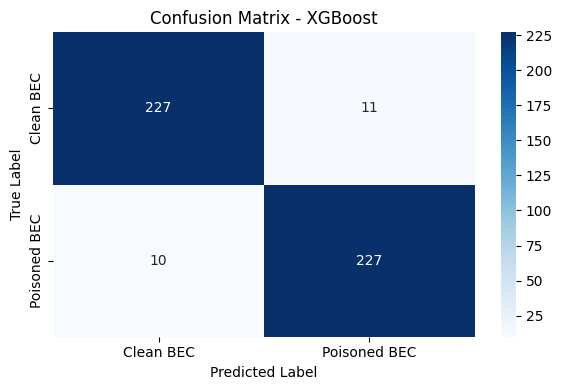

In [10]:
# ==========================================
# 9. Evaluation
# ==========================================
print("9. Evaluating model...")
y_pred = xgb_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n" + "="*35)
print("     ĐÁNH GIÁ MÔ HÌNH XGBOOST")
print("="*35)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Clean BEC (0)", "Poisoned BEC (1)"], zero_division=0))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Clean BEC", "Poisoned BEC"], 
            yticklabels=["Clean BEC", "Poisoned BEC"])
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

import os
os.makedirs("results", exist_ok=True)
plt.savefig("results/xgboost_confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()